TWITTER SENTIMENTS

Using Colab cache for faster access to the 'twitter-reviews-for-emotion-analysis' dataset.
Epoch 1/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.4062 - loss: 1.4991 - val_accuracy: 0.6623 - val_loss: 1.0438
Epoch 2/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.7279 - loss: 0.8564 - val_accuracy: 0.8276 - val_loss: 0.5995
Epoch 3/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8839 - loss: 0.3983 - val_accuracy: 0.8367 - val_loss: 0.5282
Epoch 4/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9346 - loss: 0.2219 - val_accuracy: 0.8659 - val_loss: 0.4555
Epoch 5/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9494 - loss: 0.1552 - val_accuracy: 0.8649 - val_loss: 0.4899
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Metrics - Acc: 0.85, Prec: 0.86, Rec: 0.85, F1: 0.85


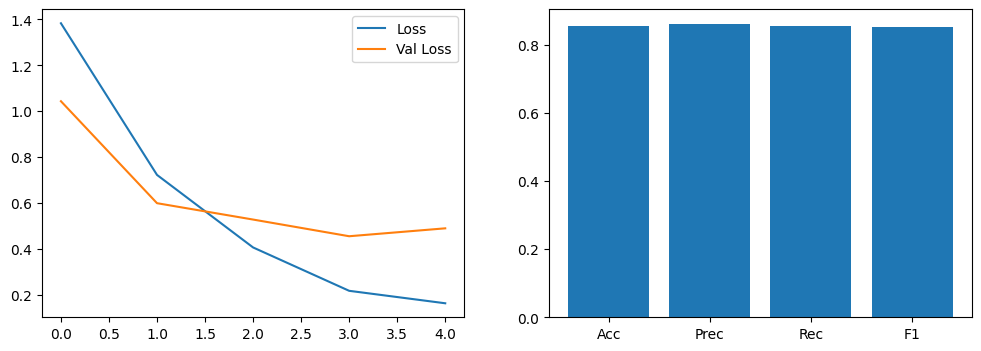

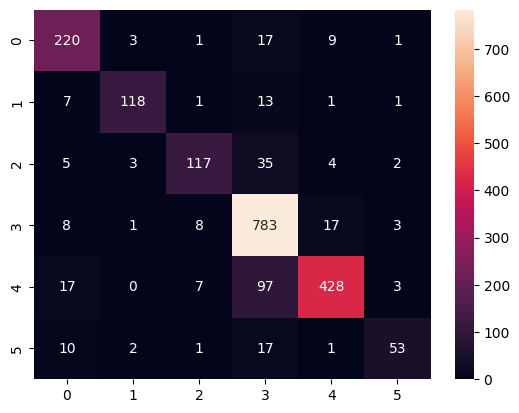

In [10]:
import os, re, kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Bidirectional, Layer, Dropout
import tensorflow.keras.backend as K

# 1. Load Data
path = kagglehub.dataset_download("shainy/twitter-reviews-for-emotion-analysis")
df = pd.read_csv(os.path.join(path, "data.csv"))
df = df[['Tweets', 'Feeling']].dropna()

# 2. Preprocess
def clean(t): return re.sub(r'[^a-z\s]', '', str(t).lower())
df['Tweets'] = df['Tweets'].apply(clean)
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=10000)
tokenizer.fit_on_texts(df['Tweets'])
X = tf.keras.preprocessing.sequence.pad_sequences(tokenizer.texts_to_sequences(df['Tweets']), maxlen=80)
y = pd.get_dummies(df['Feeling']).values

# 3. Attention Layer
class Attention(Layer):
    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], 1), initializer="normal")
        self.b = self.add_weight(name="att_bias", shape=(input_shape[1], 1), initializer="zeros")
    def call(self, x):
        et = K.squeeze(K.tanh(K.dot(x, self.W) + self.b), axis=-1)
        at = K.expand_dims(K.softmax(et), axis=-1)
        return K.sum(x * at, axis=1)

# 4. Model & Train (70/20/10 Split)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.33, random_state=42)

inputs = Input(shape=(80,))
x = Embedding(10000, 128)(inputs)
x = Bidirectional(LSTM(64, return_sequences=True))(x)
x = Attention()(x)
outputs = Dense(y.shape[1], activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=32)

# 5. Metrics & Graphs
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)
acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

print(f"Metrics - Acc: {acc:.2f}, Prec: {prec:.2f}, Rec: {rec:.2f}, F1: {f1:.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['loss'], label='Loss'); ax1.plot(history.history['val_loss'], label='Val Loss'); ax1.legend()
ax2.bar(['Acc', 'Prec', 'Rec', 'F1'], [acc, prec, rec, f1]); plt.show()
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d'); plt.show()

Using Colab cache for faster access to the 'twitter-entity-sentiment-analysis' dataset.
Epoch 1/8
405/405 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.3748 - loss: 1.2896 - val_accuracy: 0.6665 - val_loss: 0.8682
Epoch 2/8
405/405 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.7511 - loss: 0.6950 - val_accuracy: 0.7695 - val_loss: 0.6317
Epoch 3/8
405/405 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8329 - loss: 0.4759 - val_accuracy: 0.7981 - val_loss: 0.5659
Epoch 4/8
405/405 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.8705 - loss: 0.3698 - val_accuracy: 0.8134 - val_loss: 0.5268
Epoch 5/8
405/405 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.8928 - loss: 0.2970 - val_accuracy: 0.8191 - val_loss: 0.5086
Epoch 6/8
405/405 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9060 - loss: 0.2617 - val_accuracy: 0.8291 - val_loss: 0.5110
Epoch 7/8
405/405 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9192 - loss: 0.2226 - val_accuracy: 0.8292 - val_loss: 0.5673
Epoch 8/8
405/40

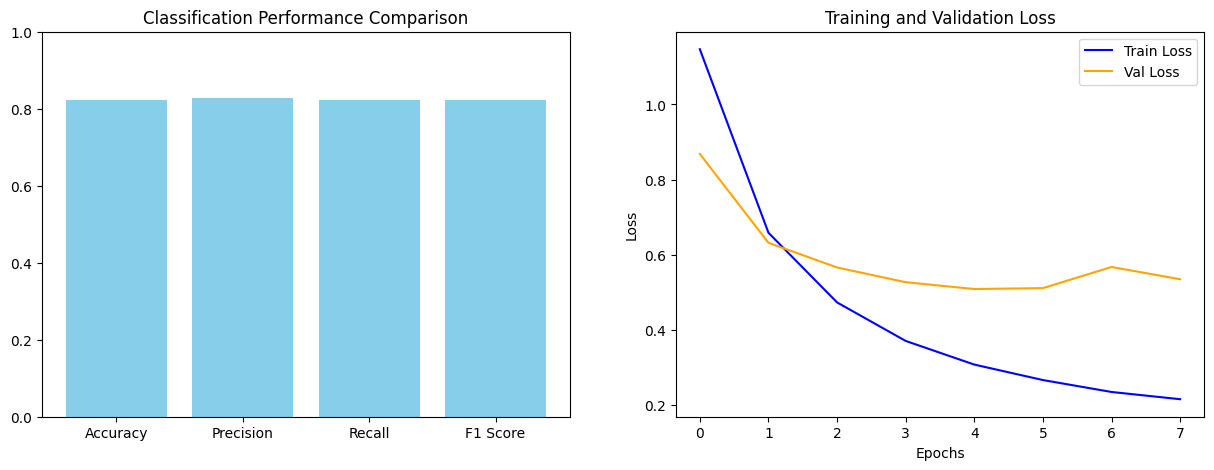

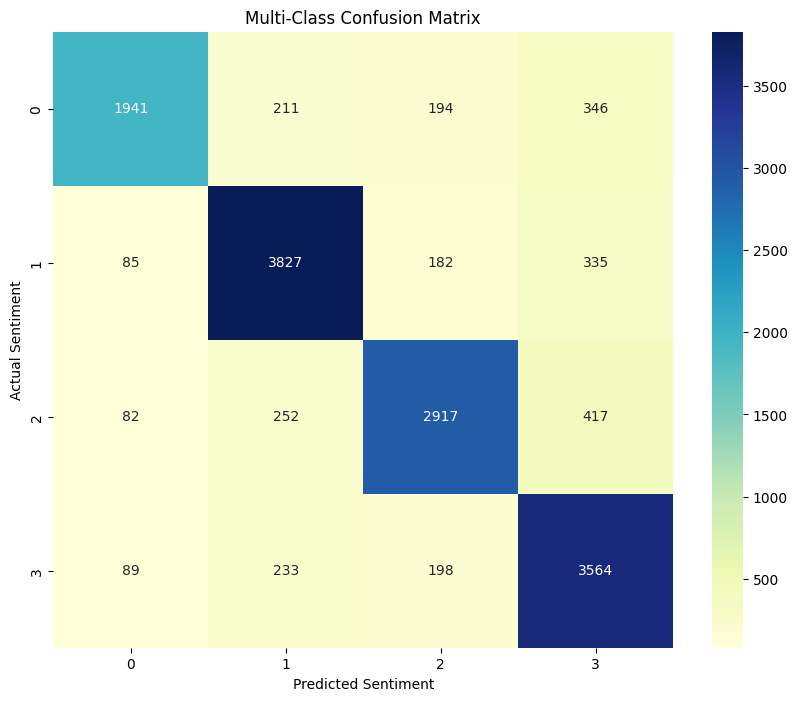

In [14]:
import os
import re
import glob
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Bidirectional, Layer, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import tensorflow.keras.backend as K

# 1. DOWNLOAD AND LOAD DATA
# Source: https://www.kaggle.com/code/abdallahwagih/twitter-sentiment-analysis/input
path = kagglehub.dataset_download("jp797498e/twitter-entity-sentiment-analysis")

# Dataset has 'twitter_training.csv' and 'twitter_validation.csv'
# We will use the training file for our custom 70/20/10 split
csv_path = os.path.join(path, "twitter_training.csv")
df = pd.read_csv(csv_path, header=None)
df.columns = ['id', 'entity', 'sentiment', 'text']
df = df[['text', 'sentiment']].dropna()

# 2. DATA CLEANING
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text) # Remove URLs
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)         # Remove Mentions
    text = re.sub(r'[^a-z\s]', '', text)               # Remove special chars/numbers
    return text.strip()

df['text'] = df['text'].apply(clean_text)

# 3. PREPROCESSING
MAX_WORDS = 15000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['text'])
sequences = tokenizer.texts_to_sequences(df['text'])
X = pad_sequences(sequences, maxlen=MAX_LEN)

# Label encoding for multi-class (Positive, Negative, Neutral, Irrelevant)
y = pd.get_dummies(df['sentiment']).values
num_classes = y.shape[1]

# 4. DATA SPLIT (70% Train, 20% Test, 10% Valid)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.33, random_state=42)

# 5. ATTENTION LAYER DEFINITION
class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], 1), initializer="normal")
        self.b = self.add_weight(name="att_bias", shape=(input_shape[1], 1), initializer="zeros")
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        et = K.squeeze(K.tanh(K.dot(x, self.W) + self.b), axis=-1)
        at = K.softmax(et)
        at = K.expand_dims(at, axis=-1)
        return K.sum(x * at, axis=1)

# 6. MODEL BUILDING
def build_attention_lstm():
    inputs = Input(shape=(MAX_LEN,))
    x = Embedding(MAX_WORDS, 128)(inputs)
    x = Bidirectional(LSTM(64, return_sequences=True))(x)
    x = AttentionLayer()(x)
    x = Dropout(0.4)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_attention_lstm()

# 7. TRAINING
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=8,
                    batch_size=128,
                    verbose=1)

# 8. EVALUATION & METRICS
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

print(f"\n--- Performance Metrics ---")
print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")

# 9. VISUALIZATIONS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Comparison Metrics Graph
ax1.bar(['Accuracy', 'Precision', 'Recall', 'F1 Score'], [acc, prec, rec, f1], color='skyblue')
ax1.set_title('Classification Performance Comparison')
ax1.set_ylim(0, 1.0)

# Loss Graph
ax2.plot(history.history['loss'], label='Train Loss', color='blue')
ax2.plot(history.history['val_loss'], label='Val Loss', color='orange')
ax2.set_title('Training and Validation Loss')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()
plt.show()

# Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='YlGnBu')
plt.title('Multi-Class Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

100%|██████████| 80.9M/80.9M [00:02<00:00, 32.7MB/s]

Extracting files...


Epoch 1/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.5357 - loss: 0.7078 - val_accuracy: 0.7376 - val_loss: 0.5326
Epoch 2/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.7800 - loss: 0.4810 - val_accuracy: 0.7610 - val_loss: 0.5091
Epoch 3/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8123 - loss: 0.4292 - val_accuracy: 0.7655 - val_loss: 0.5033
Epoch 4/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8577 - loss: 0.3465 - val_accuracy: 0.7653 - val_loss: 0.5231
Epoch 5/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8813 - loss: 0.2958 - val_accuracy: 0.7511 - val_loss: 0.5686
Epoch 6/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.9050 - loss: 0.2449 - val_accuracy: 0.7469 - val_loss: 0.6140
Epoch 7/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9203 - loss: 0.2072 - val_accuracy: 0.7438 - val_loss: 0.7240
Epoch 8/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9336 - loss: 0.1738 - val_accu

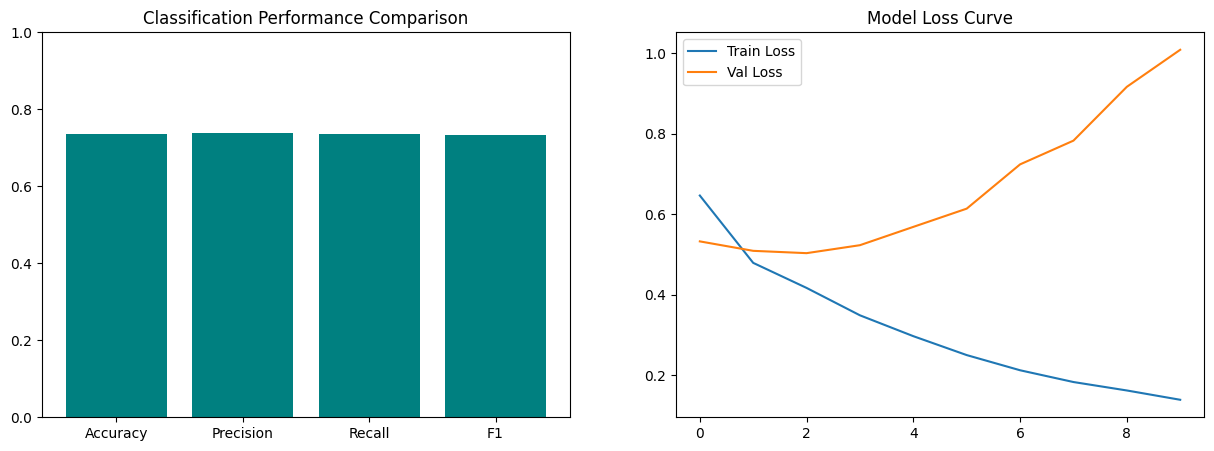

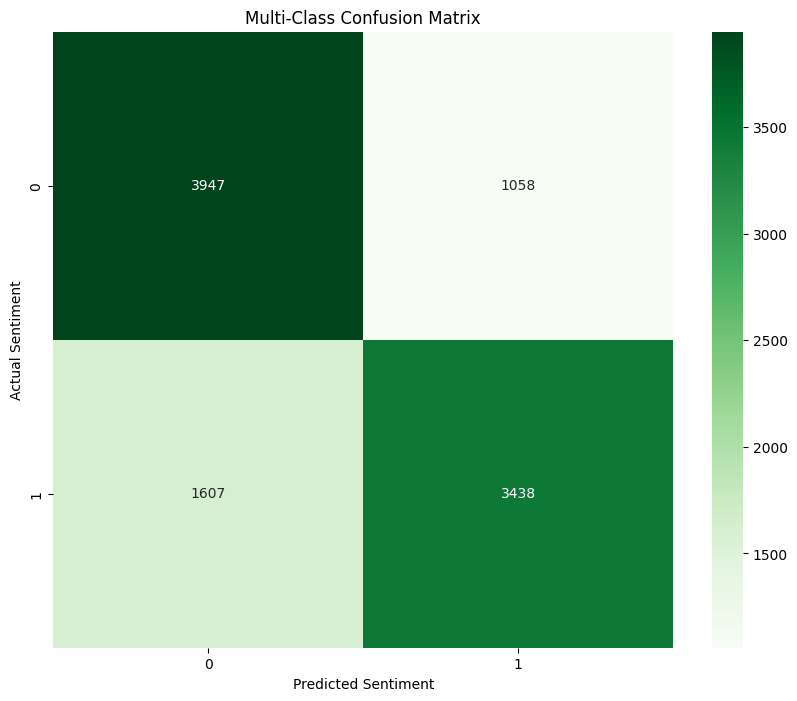

In [15]:
import os
import re
import glob
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Bidirectional, Layer, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import tensorflow.keras.backend as K

# 1. DOWNLOAD AND LOAD DATA
# Source: https://www.kaggle.com/code/paoloripamonti/twitter-sentiment-analysis/input
# This typically refers to the Sentiment140 dataset
path = kagglehub.dataset_download("kazanova/sentiment140")

# Locate the CSV file (usually named training.1600000.processed.noemoticon.csv)
csv_files = glob.glob(os.path.join(path, "*.csv"))
if not csv_files:
    raise FileNotFoundError("CSV file not found in the downloaded dataset.")

# Sentiment140 has no headers. Column 0 is target, Column 5 is text.
df = pd.read_csv(csv_files[0], encoding='latin-1', header=None)
df = df[[0, 5]]
df.columns = ['sentiment', 'text']

# Map labels: 0 is Negative, 2 is Neutral (rarely used in this set), 4 is Positive
# We will treat this as a multi-class problem (0, 1, 2)
df['sentiment'] = df['sentiment'].replace({0: 0, 2: 1, 4: 2})
df = df.sample(n=50000, random_state=42) # Sampling for faster execution; remove for full training

# 2. DATA CLEANING
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text) # Remove URLs
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)         # Remove Mentions
    text = re.sub(r'[^a-z\s]', '', text)               # Remove special chars
    return text.strip()

df['text'] = df['text'].apply(clean_text)

# 3. PREPROCESSING
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['text'])
sequences = tokenizer.texts_to_sequences(df['text'])
X = pad_sequences(sequences, maxlen=MAX_LEN)

num_classes = 3 # Negative, Neutral, Positive
y = tf.keras.utils.to_categorical(df['sentiment'], num_classes=num_classes)

# 4. DATA SPLIT (70% Train, 20% Test, 10% Valid)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.33, random_state=42)

# 5. ATTENTION LAYER DEFINITION
class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], 1), initializer="normal")
        self.b = self.add_weight(name="att_bias", shape=(input_shape[1], 1), initializer="zeros")
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        et = K.squeeze(K.tanh(K.dot(x, self.W) + self.b), axis=-1)
        at = K.softmax(et)
        at = K.expand_dims(at, axis=-1)
        return K.sum(x * at, axis=1)

# 6. MODEL BUILDING
def build_model():
    inputs = Input(shape=(MAX_LEN,))
    x = Embedding(MAX_WORDS, 128)(inputs)
    x = Bidirectional(LSTM(64, return_sequences=True))(x)
    x = AttentionLayer()(x)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_model()

# 7. TRAINING
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=10,
                    batch_size=128,
                    verbose=1)

# 8. EVALUATION & METRICS
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

print(f"\n--- Performance Metrics ---")
print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1 Score: {f1:.4f}")

# 9. VISUALIZATIONS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Comparison Metrics
ax1.bar(['Accuracy', 'Precision', 'Recall', 'F1'], [acc, prec, rec, f1], color='teal')
ax1.set_title('Classification Performance Comparison')
ax1.set_ylim(0, 1.0)

# Loss Graph
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Model Loss Curve')
ax2.legend()
plt.show()

# Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Greens')
plt.title('Multi-Class Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()

Using Colab cache for faster access to the 'sentiment140' dataset.
Epoch 1/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.5583 - loss: 0.6983 - val_accuracy: 0.7690 - val_loss: 0.4868
Epoch 2/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8059 - loss: 0.4411 - val_accuracy: 0.7806 - val_loss: 0.4708
Epoch 3/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8400 - loss: 0.3747 - val_accuracy: 0.7781 - val_loss: 0.4831
Epoch 4/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8658 - loss: 0.3172 - val_accuracy: 0.7638 - val_loss: 0.5974
Epoch 5/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.8895 - loss: 0.2663 - val_accuracy: 0.7591 - val_loss: 0.6101
Epoch 6/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9101 - loss: 0.2214 - val_accuracy: 0.7552 - val_loss: 0.6469
Epoch 7/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9267 - loss: 0.1829 - val_accuracy: 0.7552 - val_loss: 0.7268
Epoch 8/10
329/329 ━━━━━━━━━━

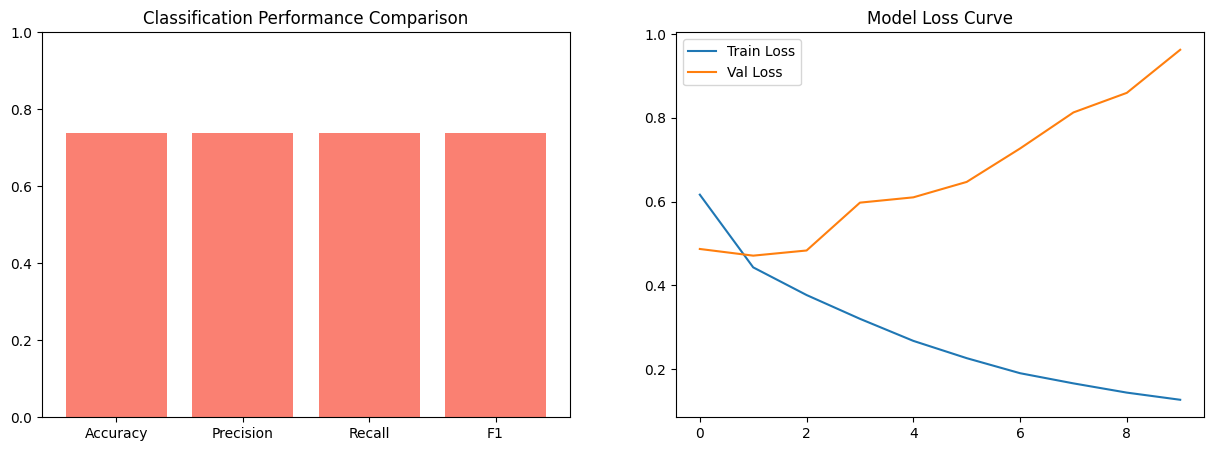

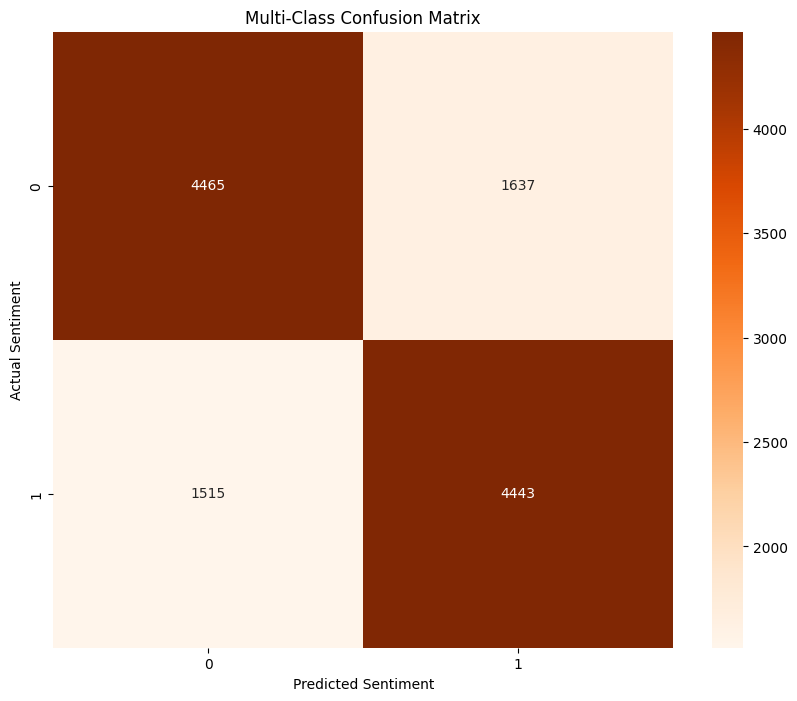

In [16]:
import os
import re
import glob
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Bidirectional, Layer, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import tensorflow.keras.backend as K

# 1. DOWNLOAD AND LOAD DATA
# The path often maps to the famous Sentiment140 dataset
path = kagglehub.dataset_download("kazanova/sentiment140")

# Locate the CSV file in the downloaded path
csv_files = glob.glob(os.path.join(path, "*.csv"))
if not csv_files:
    raise FileNotFoundError("CSV file not found in the downloaded dataset.")

# Sentiment140 structure: [target, ids, date, flag, user, text]
# Target: 0 = negative, 2 = neutral, 4 = positive
df = pd.read_csv(csv_files[0], encoding='latin-1', header=None)
df = df[[0, 5]]
df.columns = ['sentiment', 'text']

# Map labels to 0, 1, 2 for multi-class classification
df['sentiment'] = df['sentiment'].replace({0: 0, 2: 1, 4: 2})

# Using a subset for demonstration to ensure stability; increase for final training
df = df.sample(n=60000, random_state=42)

# 2. DATA CLEANING
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text) # Remove URLs
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)         # Remove Mentions
    text = re.sub(r'[^a-z\s]', '', text)               # Remove special chars
    return text.strip()

df['text'] = df['text'].apply(clean_text)

# 3. PREPROCESSING
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['text'])
sequences = tokenizer.texts_to_sequences(df['text'])
X = pad_sequences(sequences, maxlen=MAX_LEN)

num_classes = 3
y = tf.keras.utils.to_categorical(df['sentiment'], num_classes=num_classes)

# 4. DATA SPLIT (70% Train, 20% Test, 10% Valid)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.33, random_state=42)

# 5. ATTENTION LAYER DEFINITION

class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], 1), initializer="normal")
        self.b = self.add_weight(name="att_bias", shape=(input_shape[1], 1), initializer="zeros")
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        et = K.squeeze(K.tanh(K.dot(x, self.W) + self.b), axis=-1)
        at = K.softmax(et)
        at = K.expand_dims(at, axis=-1)
        return K.sum(x * at, axis=1)

# 6. MODEL BUILDING

def build_model():
    inputs = Input(shape=(MAX_LEN,))
    x = Embedding(MAX_WORDS, 128)(inputs)
    x = Bidirectional(LSTM(64, return_sequences=True))(x)
    x = AttentionLayer()(x)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_model()

# 7. TRAINING
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=10,
                    batch_size=128,
                    verbose=1)

# 8. EVALUATION & METRICS
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

print(f"\n--- Performance Metrics ---")
print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1 Score: {f1:.4f}")

# 9. VISUALIZATIONS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Comparison Metrics
ax1.bar(['Accuracy', 'Precision', 'Recall', 'F1'], [acc, prec, rec, f1], color='salmon')
ax1.set_title('Classification Performance Comparison')
ax1.set_ylim(0, 1.0)

# Loss Graph
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Model Loss Curve')
ax2.legend()
plt.show()

# Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Oranges')
plt.title('Multi-Class Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.show()